# Chargement et Prétraitement du Dataset

In [8]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ---------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [26]:
def images_to_list(path:str,images:list, labels:list):
    try:
        content_list = os.listdir(path)
        for f in content_list:
            if os.path.isdir(os.path.join(path, f)):
                # return kathbas l fonction
                images_to_list(os.path.join(path, f), images, labels)
            elif f.endswith(("jpeg", "jpg", "bmp", "png")):
                images.append(cv2.imread(os.path.join(path, f)))
                labels.append(path.split(os.sep)[-1])
    except FileNotFoundError:
        print(f"{path} :fichier introuvable.")
    except NotADirectoryError:
        print(f"{path} :n'est pas un répertoire.")
    except PermissionError:
        print(f"Besoin de permissions pour le répertoire :{path}.")
    except Exception as e:
        print(f"erreur:\n{e}")
    

In [27]:
data_dir = os.path.join("..","data")
images = []
labels = []

images_to_list(path=data_dir, images=images, labels=labels)
display(len(images), len(labels))

7023

7023

In [ ]:
# explorer les classe:
set(labels)

{'glioma', 'meningioma', 'notumor', 'pituitary'}

In [29]:
# redimensionner les images:
taille = (224, 224)
resized_images = []

for img in images:
    resized_images.append(cv2.resize(img, taille))

In [33]:
array_labels = np.array(labels)
array_labels.shape

(7023,)

In [32]:
array_resized_images = np.array(resized_images)
array_resized_images.shape

(7023, 224, 224, 3)

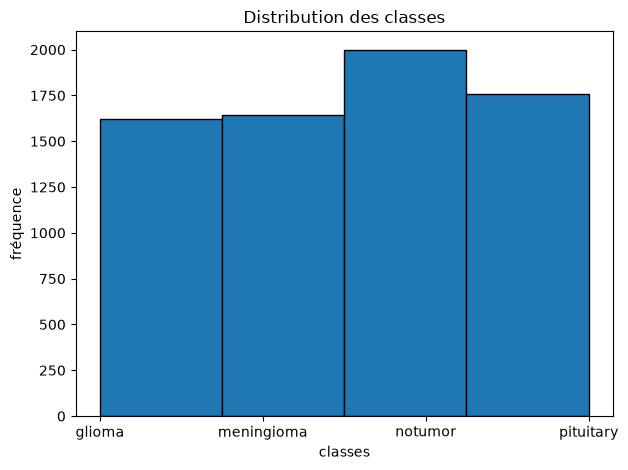

In [65]:
existing_classes, nb_y = np.unique(array_labels, return_counts=True)
plt.hist(
    labels, 
    bins=len(existing_classes), 
    edgecolor="black",
    # color=['cyan', 'Purple', 'Pink', 'Blue']
)
plt.title("Distribution des classes")
plt.xlabel("classes")
plt.ylabel("fréquence")

plt.tight_layout()
plt.show()

In [66]:
nb_y

array([1621, 1645, 2000, 1757])

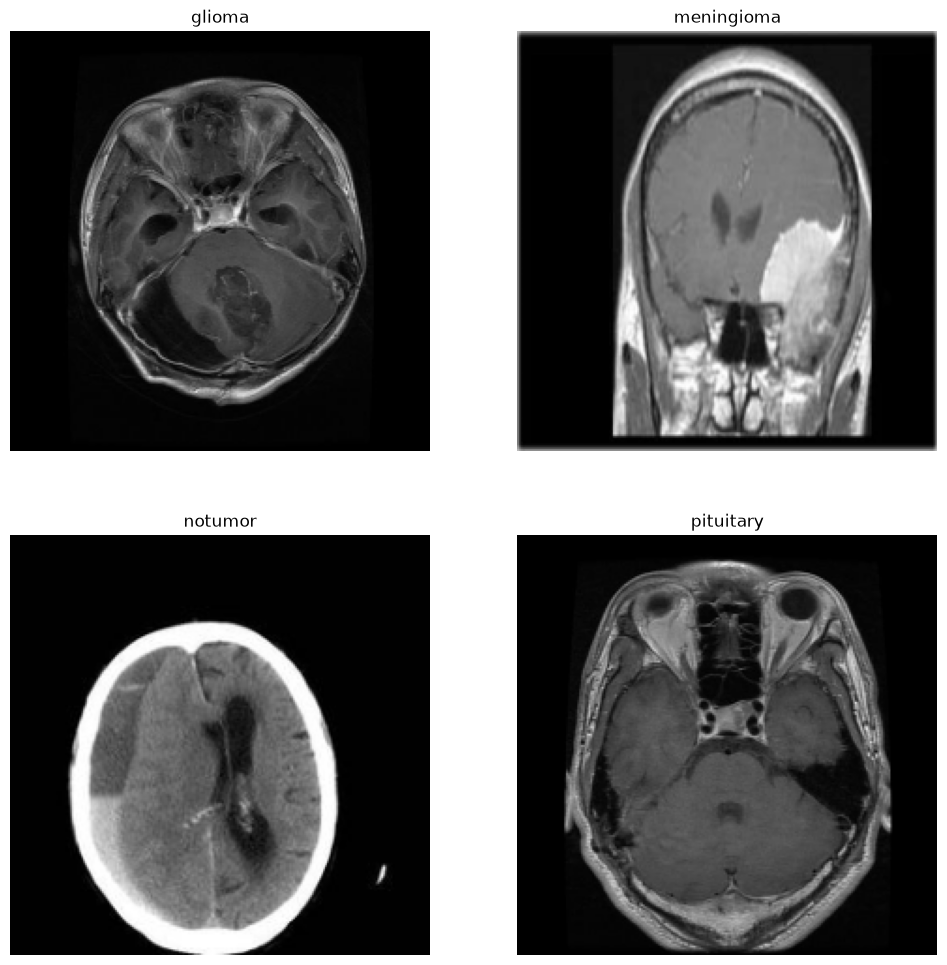

In [64]:
# Montrer un échantillon d’images pour chaque classe.
echantillon = {}
for classe in existing_classes:
    echantillon[classe] = labels.index(classe)

fig, axs = plt.subplot_mosaic([['img1', 'img2'], ['img3', 'img4']], figsize=(12, 12))
i=1
for k, v in echantillon.items():
    axs[f"img{i}"].imshow(array_resized_images[v])
    axs[f"img{i}"].set_title(k)
    axs[f"img{i}"].axis("off")
    i+=1

plt.show()

Pour le moment et selon la recherche + le histogram le dataset est équilibré.